In [203]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
from sklearn. linear_model import LogisticRegression 
from sklearn. svm import SVC
from sklearn. tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report 
df = pd.read_csv("heart_disease_uci.csv")

In [204]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [205]:
# Initialize the dataset
df = pd.read_csv("heart_disease_uci.csv")

# Create binary target
df["target"] = (df["num"] > 0).astype(int)


In [206]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,0


In [207]:
df.tail()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2,1
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0,0
919,920,62,Male,VA Long Beach,atypical angina,120.0,254.0,False,lv hypertrophy,93.0,True,0.0,NaN,NaN,NaN,1,1


In [208]:
df.sample(5)  #shuffled 5 rows

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
89,90,51,Female,Cleveland,non-anginal,130.0,256.0,False,lv hypertrophy,149.0,False,0.5,upsloping,0.0,normal,0,0
661,662,57,Male,Switzerland,asymptomatic,110.0,0.0,NaN,st-t abnormality,131.0,True,1.4,upsloping,1.0,NaN,3,1
453,454,54,Male,Hungary,atypical angina,120.0,246.0,False,normal,110.0,False,0.0,NaN,NaN,NaN,0,0
197,198,45,Female,Cleveland,asymptomatic,138.0,236.0,False,lv hypertrophy,152.0,True,0.2,flat,0.0,normal,0,0
208,209,55,Male,Cleveland,atypical angina,130.0,262.0,False,normal,155.0,False,0.0,upsloping,0.0,normal,0,0


In [209]:
print(f"There are {df.shape[0]} number of rows, and {df.shape[1]} number of columns in the data")

There are 920 number of rows, and 17 number of columns in the data


In [210]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num,target
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652,0.553261
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693,0.497426
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000,1.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000,1.000000


In [211]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,920.0,460.500000,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.130337,110.780810,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.545665,25.926276,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.676375,0.935653,0.0,0.00,0.0,1.00,3.0
num,920.0,0.995652,1.142693,0.0,0.00,1.0,2.00,4.0
target,920.0,0.553261,0.497426,0.0,0.00,1.0,1.00,1.0


In [212]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
 16  target    920 non-null    int64  
dtypes: float64(5), int64(4), object(2), str(6)
memory usage: 163.6+ KB


In [213]:
df.isna().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
target        0
dtype: int64

In [214]:
df.duplicated().sum()

np.int64(0)

In [215]:
df = df.drop(columns=["id"])

In [216]:
df = df.drop(columns=["dataset"])

In [217]:
df = df.drop(columns=["num"])

In [218]:
df.isna().mean() * 100

age          0.000000
sex          0.000000
cp           0.000000
trestbps     6.413043
chol         3.260870
fbs          9.782609
restecg      0.217391
thalch       5.978261
exang        5.978261
oldpeak      6.739130
slope       33.586957
ca          66.413043
thal        52.826087
target       0.000000
dtype: float64

In [219]:
df.dtypes

age           int64
sex             str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
target        int64
dtype: object

In [220]:
for col in df.columns:
    print("\n", col)
    print(df[col].unique())


 age
[63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76 28 30 31 32 33 36 72
 73 75]

 sex
<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

 cp
<ArrowStringArray>
['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina']
Length: 4, dtype: str

 trestbps
[145. 160. 120. 130. 140. 172. 150. 110. 132. 117. 135. 112. 105. 124.
 125. 142. 128. 170. 155. 104. 180. 138. 108. 134. 122. 115. 118. 100.
 200.  94. 165. 102. 152. 101. 126. 174. 148. 178. 158. 192. 129. 144.
 123. 136. 146. 106. 156. 154. 114. 164.  98. 190.  nan 113.  92.  95.
  80. 185. 116.   0.  96. 127.]

 chol
[233. 286. 229. 250. 204. 236. 268. 354. 254. 203. 192. 294. 256. 263.
 199. 168. 239. 275. 266. 211. 283. 284. 224. 206. 219. 340. 226. 247.
 167. 230. 335. 234. 177. 276. 353. 243. 225. 302. 212. 330. 175. 417.
 197. 198. 290. 253. 172. 273. 213. 305. 216. 304. 188. 282. 185. 232.
 326. 231. 269. 267. 248. 360. 258. 308. 

In [221]:
df["target"].value_counts()

target
1    509
0    411
Name: count, dtype: int64

In [222]:
df["target"].value_counts(normalize=True) * 100

target
1    55.326087
0    44.673913
Name: proportion, dtype: float64

In [223]:
import seaborn as sns

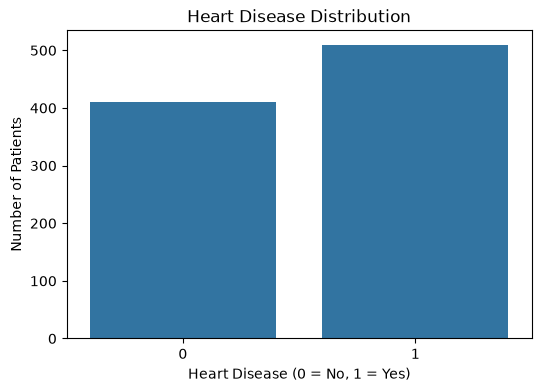

In [224]:
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df)
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

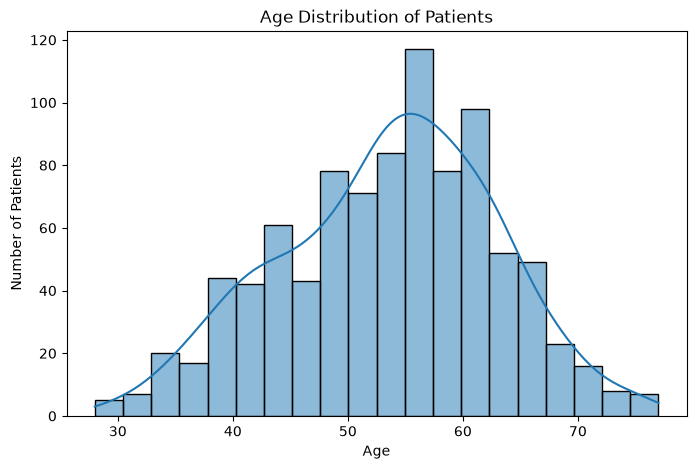

In [225]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

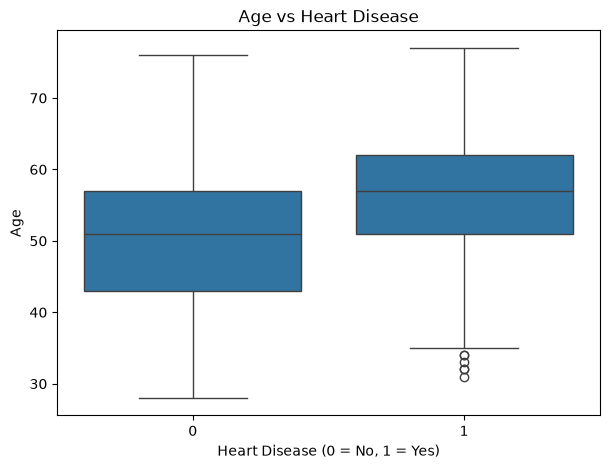

In [226]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="target", y="age", data=df)
plt.title("Age vs Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()

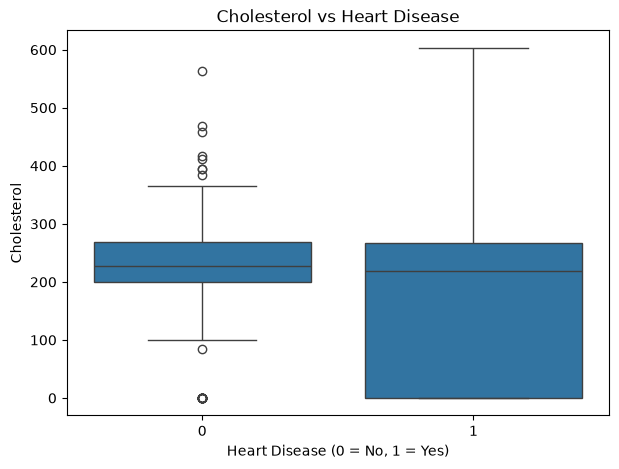

In [227]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="target", y="chol", data=df)
plt.title("Cholesterol vs Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Cholesterol")
plt.show()

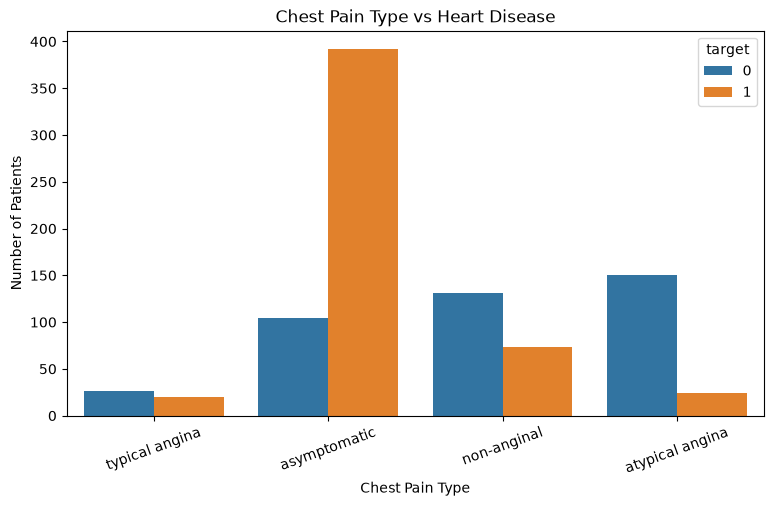

In [228]:
plt.figure(figsize=(9, 5))
sns.countplot(x="cp", hue="target", data=df)
plt.title("Chest Pain Type vs Heart Disease")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.xticks(rotation=20)
plt.show()

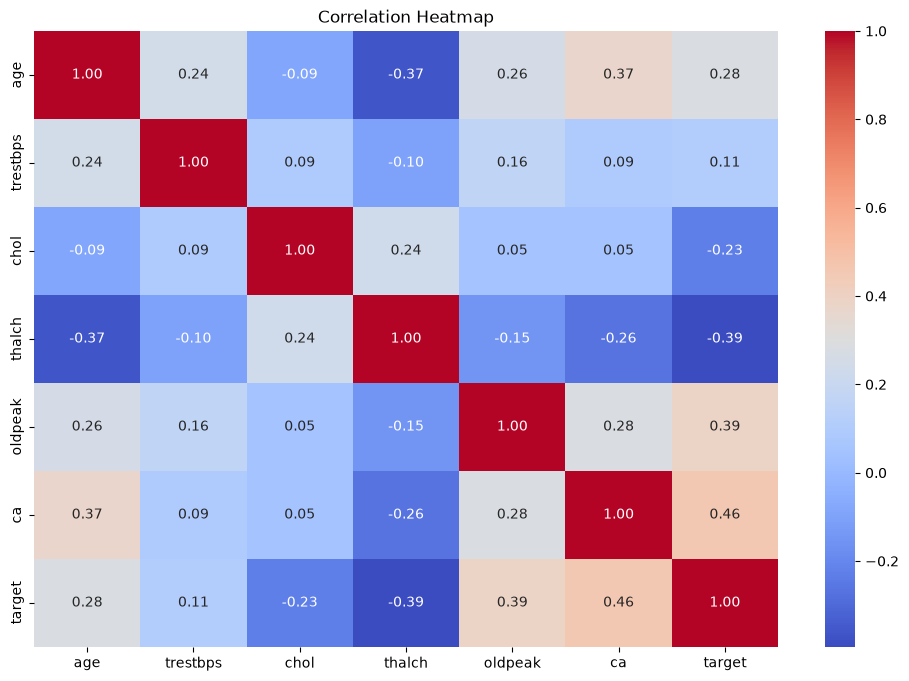

In [229]:
numeric_cols = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [230]:
df.dtypes

age           int64
sex             str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
target        int64
dtype: object

In [231]:
numeric_features = [
    "age", "trestbps", "chol",
    "thalch", "oldpeak", "ca"
]

categorical_features = [
    "sex", "cp", "fbs",
    "restecg", "exang", "slope", "thal"
]

In [232]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [233]:
X = df.drop("target", axis=1)
y = df["target"]

In [234]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [235]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [236]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [237]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [238]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [239]:
models = {
    "Logistic Regression": LogisticRegression(),
    "SVM (Linear)": SVC(kernel='linear'),
    "SVM (RBF)": SVC(kernel='rbf'),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier()
}

In [240]:
# store the results(outputs) in results list
results = []

In [241]:
models.items()

dict_items([('Logistic Regression', LogisticRegression()), ('SVM (Linear)', SVC(kernel='linear')), ('SVM (RBF)', SVC()), ('Decision Tree', DecisionTreeClassifier()), ('Random Forest', RandomForestClassifier()), ('KNN', KNeighborsClassifier())])

In [242]:
for name, model in models.items():
    
    # fit and train the models
    model.fit(X_train, y_train)
    
    # prediction on the training data
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    results.append({ 
        "Models": name,
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision Score": precision_score(y_test, test_pred), # out of all predicted 1, how many were actually 1
        "Recall Score": recall_score(y_test, test_pred), # out of all 1s, how many model captured as 1
        "F1 Score": f1_score(y_test, test_pred)  # harmonic mean between precision and recall
                    
    })

In [243]:
# convert the list "result" into dataframes
results_df = pd.DataFrame(results).sort_values(by="Test Accuracy", ascending=False)
results_df = round(results_df, 3)

In [244]:
results_df

,Models,Training Accuracy,Test Accuracy,Precision Score,Recall Score,F1 Score
4,Random Forest,1.000,0.864,0.853,0.912,0.882
0,Logistic Regression,0.821,0.842,0.841,0.882,0.861
2,SVM (RBF),0.885,0.842,0.817,0.922,0.866
1,SVM (Linear),0.825,0.837,0.833,0.882,0.857
5,KNN,0.872,0.826,0.830,0.863,0.846
3,Decision Tree,1.000,0.750,0.769,0.784,0.777


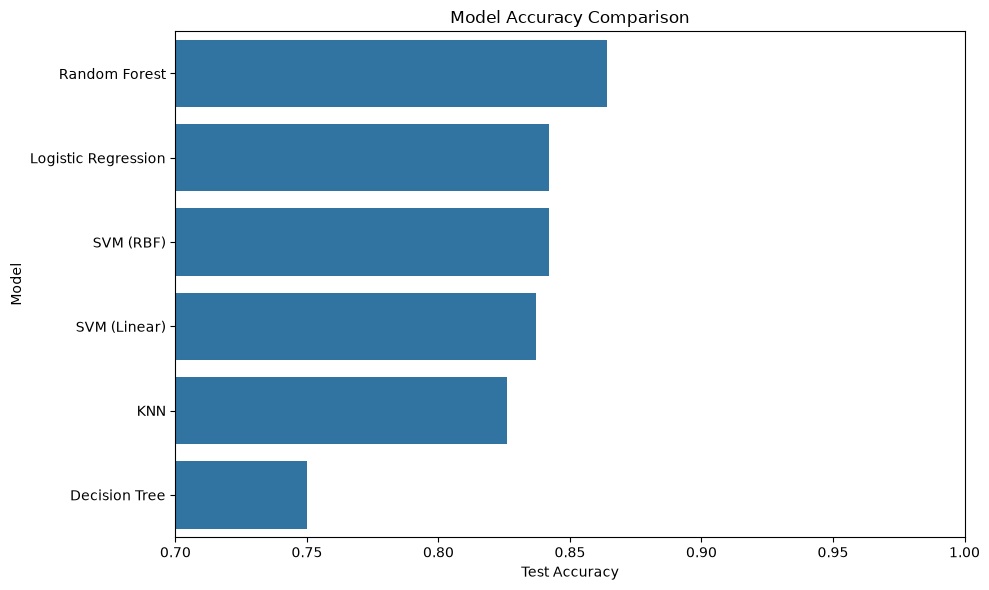

In [245]:
# Visualize the comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    x="Test Accuracy",
    y="Models",
    data=results_df
)

plt.title("Model Accuracy Comparison")
plt.xlim(0.7, 1.0)
plt.xlabel("Test Accuracy")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

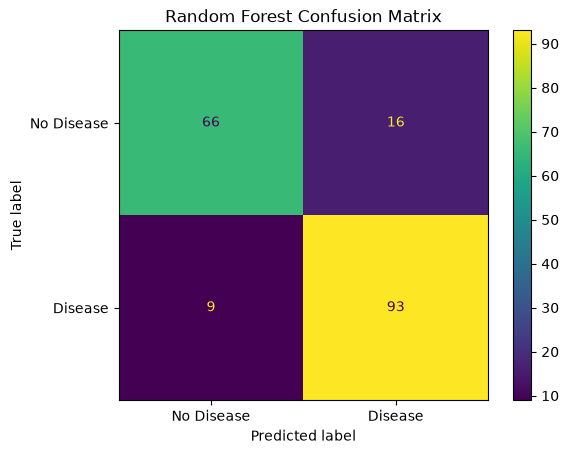

In [246]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Random Forest
rf_model = models["Random Forest"]
rf_pred = rf_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No Disease", "Disease"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

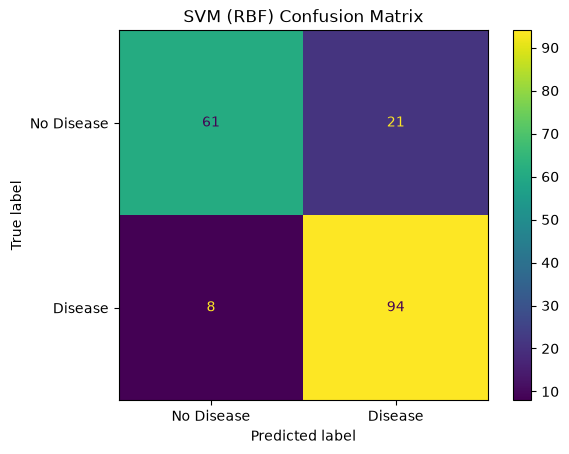

In [247]:
svm_model = models["SVM (RBF)"]
svm_pred = svm_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_pred,
    display_labels=["No Disease", "Disease"]
)

plt.title("SVM (RBF) Confusion Matrix")
plt.show()

In [248]:
print("Random Forest")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Disease", "Disease"]
))

Random Forest
              precision    recall  f1-score   support

  No Disease       0.88      0.80      0.84        82
     Disease       0.85      0.91      0.88       102

    accuracy                           0.86       184
   macro avg       0.87      0.86      0.86       184
weighted avg       0.87      0.86      0.86       184



In [249]:
print("SVM (RBF)")
print(classification_report(
    y_test,
    svm_pred,
    target_names=["No Disease", "Disease"]
))

SVM (RBF)
              precision    recall  f1-score   support

  No Disease       0.88      0.74      0.81        82
     Disease       0.82      0.92      0.87       102

    accuracy                           0.84       184
   macro avg       0.85      0.83      0.84       184
weighted avg       0.85      0.84      0.84       184



In [250]:
best_model_name = results_df.loc[
    results_df["Test Accuracy"].idxmax(),
    "Models"
]

print(f"The Best Model is: {best_model_name}")

The Best Model is: Random Forest


In [251]:
import joblib

# Get the actual trained model
best_model = models[best_model_name]

model_file_name = "heart_disease_model.joblib"
preprocessor_filename = "heart_disease_preprocessor.joblib"

# Save actual trained model
joblib.dump(best_model, model_file_name)

# Save preprocessing pipeline
joblib.dump(preprocessor, preprocessor_filename)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [252]:
loaded_model = joblib.load("heart_disease_model.joblib")

print(type(loaded_model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [253]:
import os

print(os.path.exists("heart_disease_model.joblib"))
print(os.path.exists("heart_disease_preprocessor.joblib"))

True
True


In [254]:
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,target
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
5,56,Male,atypical angina,120.0,236.0,False,normal,178.0,False,0.8,upsloping,0.0,normal,0
6,62,Female,asymptomatic,140.0,268.0,False,lv hypertrophy,160.0,False,3.6,downsloping,2.0,normal,1
7,57,Female,asymptomatic,120.0,354.0,False,normal,163.0,True,0.6,upsloping,0.0,normal,0
8,63,Male,asymptomatic,130.0,254.0,False,lv hypertrophy,147.0,False,1.4,flat,1.0,reversable defect,1
9,53,Male,asymptomatic,140.0,203.0,True,lv hypertrophy,155.0,True,3.1,downsloping,0.0,reversable defect,1
